# COMPAS

Realizable Surrogate on COMPAS, whose human predictions are the majority vote of Mechanical
Turk participants (`fig:compas_explanation`). The expert model is fitted by
MLE on the 700 training cases; alpha and the threshold are selected on the 100 validation
cases; all deferred cases among the 200 test cases are searched. There is no known expert,
so this notebook has no `EXPERT` switch.

Cached in `cache/compas/` (`core.run_compas`). Outputs: `figures/compas_expert_roc.pdf`
and the values shown in the two examples of `fig:compas_explanation`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import log_loss, roc_auc_score, roc_curve

import core

SEED = 0
torch.set_num_threads(1)
core.run_compas(SEED)
expert = core.experts("compas", None, SEED)["fitted"]
pairs, info = core.load_run(core.compas_path(SEED))
pairs = core.assign_types(pairs, expert)
raw, x, data, scaler = core.load_compas(SEED)
pairs["source_row"] = np.asarray(data.test_x.indices)[pairs["test_index"]]
pairs["source_id"] = raw["id"].to_numpy()[pairs["source_row"]]
print(f"{int(pairs.found.sum())}/{len(pairs)} deferred test cases have a counterfactual; {info['n_test']} test cases.")
print(pairs.loc[pairs.found, "category"].value_counts().to_string())

135/136 deferred test cases have a counterfactual; 200 test cases.
category
type_i    129
mixed       6


## Fitted expert on the held-out test cases

Human-label fidelity: the human prediction against P(h(x)=1 | y, x). Human-error
discrimination: the human error against P(h(x)≠y | y, x). Both condition on the true label.

Human-label fidelity: AUC = 0.973, log loss = 0.213
Human-error discrimination: AUC = 0.971, log loss = 0.213


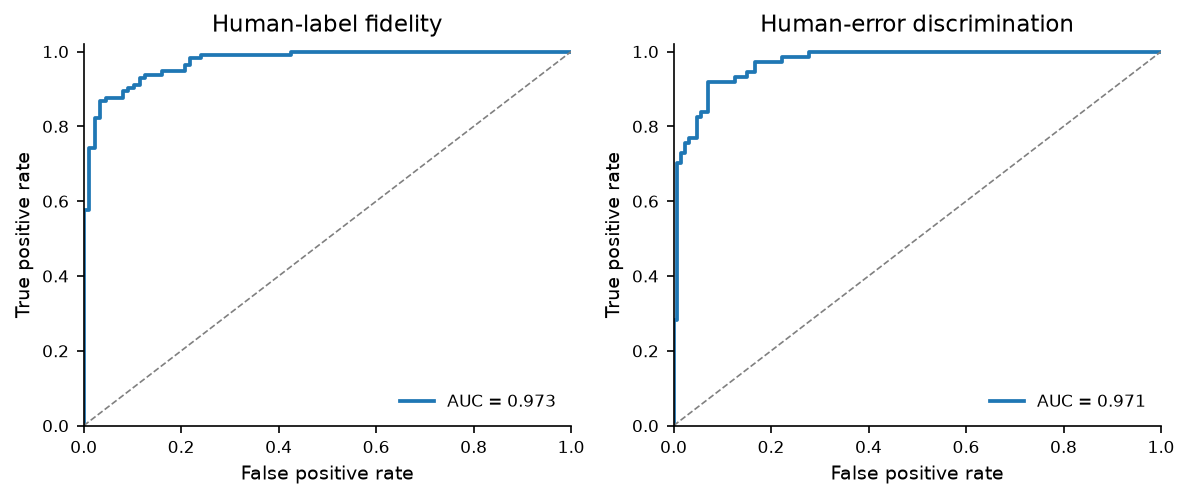

In [2]:
test_x, test_y, test_h = (t.numpy() for t in data.data_test.tensors)
error = expert.error_probabilities(test_x)[np.arange(len(test_y)), test_y]
targets = [("Human-label fidelity", test_h, np.where(test_y == 0, error, 1 - error)),
           ("Human-error discrimination", (test_h != test_y).astype(int), error)]
plt.rcParams.update({"font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42})
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.4), dpi=150)
for ax, (title, target, probability) in zip(axes, targets):
    auc = roc_auc_score(target, probability)
    fpr, tpr, _ = roc_curve(target, probability)
    print(f"{title}: AUC = {auc:.3f}, log loss = {log_loss(target, probability, labels=[0, 1]):.3f}")
    ax.plot(fpr, tpr, color="#1F77B4", linewidth=1.8, label=f"AUC = {auc:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=0.8)
    ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False positive rate", ylabel="True positive rate", title=title)
    ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()
core.FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(core.FIGURES / "compas_expert_roc.pdf", bbox_inches="tight")
plt.show()

## Values for the two examples in `fig:compas_explanation`

Feature values in original units; only features whose two-decimal values differ are listed.
The search is continuous and does not enforce integer, categorical or immutable features.

In [3]:
NAMES = {"race": "Race code", "sex": "Sex code", "age": "Age", "juv_fel_count": "Juvenile felonies",
         "juv_misd_count": "Juvenile misdemeanors", "priors_count": "Prior offenses", "charge_id": "Charge ID code",
         "charge_degree (misd/fel)": "Charge degree code", "compas_decile_score": "COMPAS score"}


def shown(value):
    text = f"{float(value):.2f}"
    return "0.00" if text == "-0.00" else text


def example(category, source_id):
    [i] = np.flatnonzero(pairs["found"] & (pairs["source_id"] == source_id) & (pairs["category"] == category))
    row = pairs.iloc[i]
    counterfactual = core.points(pairs, "cf")[i] * scaler.scale_ + scaler.mean_
    print(f"{category} | COMPAS case {source_id}")
    print(f"  Uncertainty: {shown(row.uncertainty_x)} -> {shown(row.uncertainty_cf)}")
    print(f"  Estimated expert performance: {shown(100 * row.expert_performance_x)}% -> {shown(100 * row.expert_performance_cf)}%")
    for j, feature in enumerate(x.columns):
        before, after = shown(raw[feature].iloc[row.source_row]), shown(counterfactual[j])
        if before != after:
            print(f"  {NAMES.get(feature, feature)}: {before} -> {after}")


example("type_i", 266)
example("mixed", 319)

type_i | COMPAS case 266
  Uncertainty: 0.31 -> 0.29
  Estimated expert performance: 65.29% -> 74.68%
  Age: 54.00 -> 53.99
  Prior offenses: 2.00 -> 1.72
  Charge ID code: 65.00 -> 64.95
mixed | COMPAS case 319
  Uncertainty: 0.65 -> 0.41
  Estimated expert performance: 35.13% -> 14.55%
  Sex code: 0.00 -> 0.22
  Prior offenses: 7.00 -> 5.34
  Charge ID code: 172.00 -> 171.97
